# The single signal SDE

Here, we simulate the SDE

$$dS = (E(S)N - \delta S)\, dt + \sqrt{E(S)N + \delta S}\, dw, \quad \text{ where } \quad E(S) = \rho + \frac{\alpha S^2}{S^2 + K^2}$$

### Simulation of trajectories using the Euler Method:
$$S(t + \Delta t) = S(t) + \mu(S(t))\Delta t + \sigma(S(t)) \sqrt{\Delta t}\, \eta(t),$$
where $\eta(t) \sim N(0,1)$ is sampled from a normal distribution at each time.

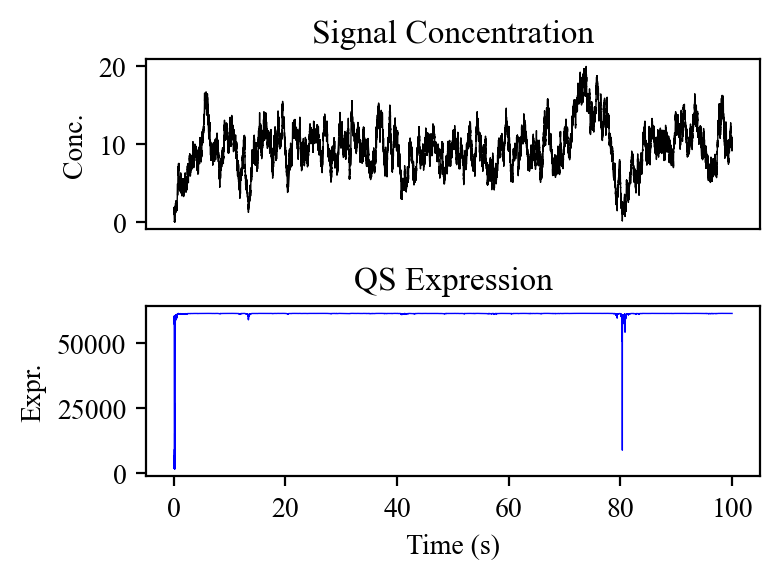

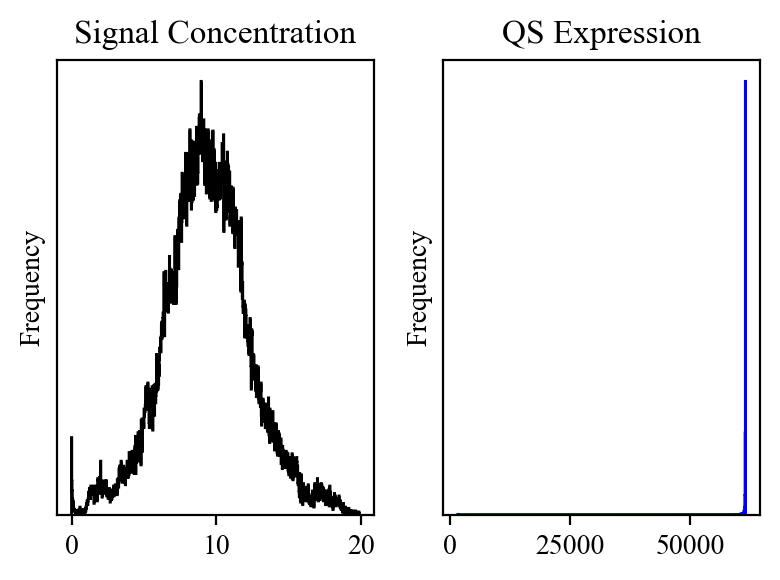

In [36]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 10

S0 = 1
dt = 0.001
tmax = 100

# Parameters
rho = 1600 # in [100, 2,000]
alpha = 60000 # in [10,000, 100,000]
K = 0.25 # in [0,1]
delta = 1 # in [0,2]
N = 1 # in [0,2]
c = 1.5e-4 # in [1e-6, 1e-4]

def QS_expression(S):
    return rho + (alpha*np.pow(S,2)) / (np.pow(K,2) + np.pow(S,2))

def mu(S):
    return c*QS_expression(S)*N - delta*S

def sigma(S):
    return np.sqrt(c*QS_expression(S)*N + delta*S)

def Euler_step(S, dt):
    return S + mu(S)*dt + sigma(S)*np.sqrt(dt)*np.random.normal()

num_time_steps = int(tmax / dt)
t_array = np.arange(0, tmax, dt)
S_time_series = np.zeros(num_time_steps)
S_time_series[0] = S0

for i in range(1, num_time_steps):
    S_time_series[i] = Euler_step(S_time_series[i-1], dt)
    if S_time_series[i] < 0: S_time_series[i] = 0 # boundary condition

QS_expression_time_series = QS_expression(S_time_series)
fig, axes = plt.subplots(2, 1, figsize=(4,3), dpi=200)

ax1, ax2 = axes
ax1.plot(t_array, S_time_series, label=r'$S(t)$', color='k', linewidth=0.5)
ax2.plot(t_array, QS_expression_time_series, label=r'$E(t)$', color='b', linewidth=0.5)

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

ax1.set_ylabel('Conc.')
ax2.set_ylabel('Expr.')

ax1.set_xticks([])
ax2.set_xlabel('Time (s)')

plt.tight_layout()
plt.savefig('Figures/single-signal-SDE-time-series.png', bbox_inches='tight')

fig, axes = plt.subplots(1, 2, figsize=(4,3), dpi=200)

ax1, ax2 = axes

num_hist_bins = 1000
ax1.hist(S_time_series, bins=num_hist_bins, histtype='step', color='k')
ax2.hist(QS_expression_time_series, bins=num_hist_bins, histtype='step', color='b')

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

[ax.set_ylabel('Frequency') for ax in axes]
[ax.set_yticks([]) for ax in axes]

fig.tight_layout()

plt.savefig('Figures/single-signal-SDE-time-series-distributions.png', bbox_inches='tight')

### The single-signal, single-expression SDE:
$$\begin{align}
    dS & = (cEN - \delta S)\, dt + \sqrt{cEN + \delta S}\, dw_1 \\
    dE & = \left( \rho + \frac{\alpha S^2}{S^2 + K^2} - E \right)\, \frac{dt}{T} + \left( \sqrt{\rho + \frac{\alpha S^2}{S^2 + K^2} + E} \right)\, \frac{dw_2}{\sqrt{T}}
\end{align}$$
We can simulate this using the Euler method. Setting
$$\begin{align}
    \mu_S(S,E) & = cEN - \delta S, & \sigma_S(S,E) & = \sqrt{cEN + \delta S}, \\
    \mu_E(S,E) & = \rho + \frac{\alpha S^2}{S^2 + K^2} - E, & \qquad \sigma_E(S,E) & = \rho + \frac{\alpha S^2}{S^2 + K^2} + E,
\end{align}$$
the Euler method can be written as
$$\begin{align}
    S(t + \Delta t) & = S(t) + \mu_S(S(t),E(t))\Delta t + \sigma_S(S(t),E(t))\sqrt{\Delta t}\eta_1(t) \\
    E(t + \Delta t) & = E(t) + \mu_E(S(t),E(t))\frac{\Delta t}{T} + \sigma_E(S(t),E(t))\sqrt{\frac{\Delta t}{T}}\eta_2(t)
\end{align}$$

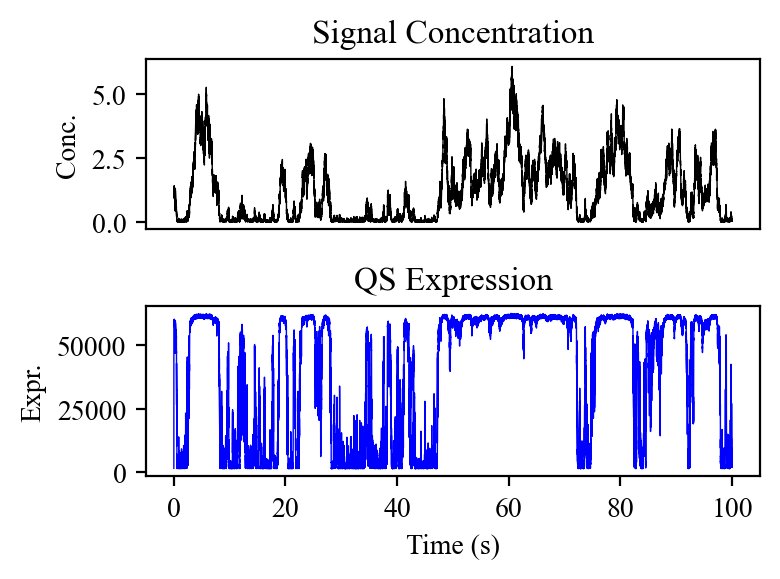

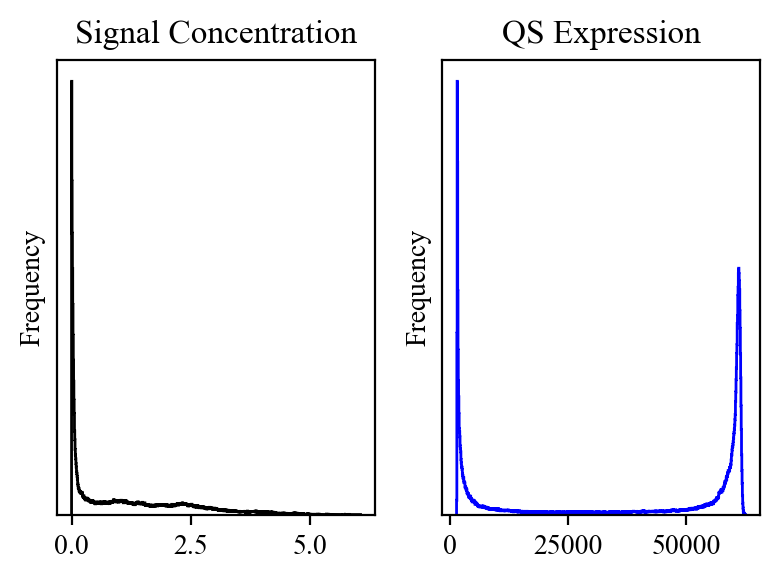

In [161]:
S0 = 1
E0 = 1600
dt = 0.0002
tmax = 100

# Parameters
rho = 1600 # in [100, 2,000]
alpha = 60000 # in [10,000, 100,000]
K = 0.25 # in [0,1]
delta = 0.6 # in [0,2]
N = 1.5 # in [0,2]
c = 1e-5 # in [1e-6, 1e-4]
T = 1e-3 # Not sure of the parameter range

def QS_expression(S):
    return rho + (alpha*np.pow(S,2)) / (np.pow(K,2) + np.pow(S,2))

def mu_S(S,E):
    return c*E*N - delta*S

def sigma_S(S,E):
    return np.sqrt(c*E*N + delta*S)

def mu_E(S,E):
    return QS_expression(S) - E

def sigma_E(S,E):
    return np.sqrt(QS_expression(S) + E)

def Euler_step(X, dt):
    S, E = X
    S = S + mu_S(S,E)*dt + sigma_S(S,E)*np.sqrt(dt)*np.random.normal()
    E = E + mu_E(S,E)*dt/T + sigma_E(S,E)*np.sqrt(dt/T)*np.random.normal()
    return np.array([S, E])

num_time_steps = int(tmax / dt)
t_array = np.arange(0, tmax, dt)
sol_array = np.zeros((2, num_time_steps))
sol_array[:,0] = np.array([S0, E0])

for i in range(1, num_time_steps):
    sol_array[:,i] = Euler_step(sol_array[:,i-1], dt)
    if sol_array[0,i] < 0: sol_array[0,i] = 0 # boundary condition
    if sol_array[1,i] < 0: sol_array[1,i] = 0 # boundary condition

S_time_series = sol_array[0]
E_time_series = sol_array[1]

fig, axes = plt.subplots(2, 1, figsize=(4,3), dpi=200)

ax1, ax2 = axes
ax1.plot(t_array, S_time_series, label=r'$S(t)$', color='k', linewidth=0.5)
ax2.plot(t_array, E_time_series, label=r'$E(t)$', color='b', linewidth=0.5)

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

ax1.set_ylabel('Conc.')
ax2.set_ylabel('Expr.')

ax1.set_xticks([])
ax2.set_xlabel('Time (s)')

plt.tight_layout()
plt.savefig('Figures/signal-and-expression-SDE-time-series.png', bbox_inches='tight')

fig, axes = plt.subplots(1, 2, figsize=(4,3), dpi=200)

ax1, ax2 = axes

num_hist_bins = 1000
ax1.hist(S_time_series, bins=num_hist_bins, histtype='step', color='k')
ax2.hist(E_time_series, bins=num_hist_bins, histtype='step', color='b')

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

[ax.set_ylabel('Frequency') for ax in axes]
[ax.set_yticks([]) for ax in axes]

fig.tight_layout()

plt.savefig('Figures/signal-and-expression-SDE-time-series-distributions.png', bbox_inches='tight')

### The single-signal, single-expression SDE using a population average:
$$\begin{align}
    dS & = (c\langle E \rangle N - \delta S)\, dt + \sqrt{c\langle E \rangle N + \delta S}\, dw_1 \\
    dE & = \left( \rho + \frac{\alpha S^2}{S^2 + K^2} - E \right)\, \frac{dt}{T} + \left( \sqrt{\rho + \frac{\alpha S^2}{S^2 + K^2} + E} \right)\, \frac{dw_2}{\sqrt{T}}
\end{align}$$
We can simulate this using the Euler method. Setting
$$\begin{align}
    \mu_S(S) & = c\langle E \rangle N - \delta S, & \sigma_S(S) & = \sqrt{c\langle E \rangle N + \delta S}, & \qquad \text{ where } \langle E \rangle & = \rho + \frac{\alpha S^2}{S^2 + K^2} \\
    \mu_E(S,E) & = \langle E \rangle - E, & \qquad \sigma_E(S,E) & = \langle E \rangle + E,
\end{align}$$
the Euler method can be written as
$$\begin{align}
    S(t + \Delta t) & = S(t) + \mu_S(S(t))\Delta t + \sigma_S(S(t))\sqrt{\Delta t}\eta_1(t) \\
    E(t + \Delta t) & = E(t) + \mu_E(S(t),E(t))\frac{\Delta t}{T} + \sigma_E(S(t),E(t))\sqrt{\frac{\Delta t}{T}}\eta_2(t)
\end{align}$$

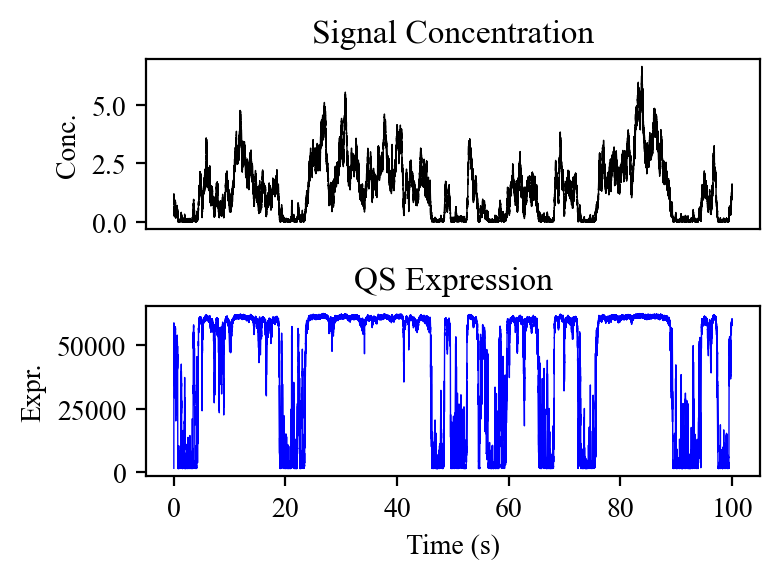

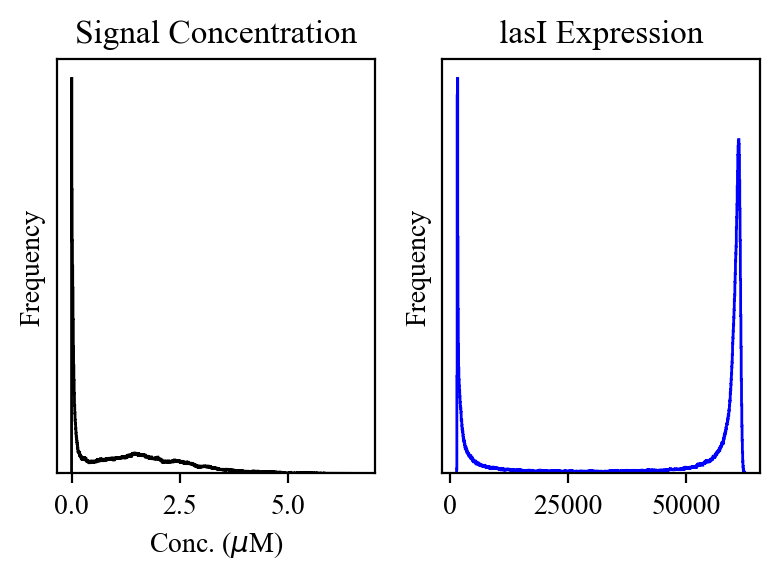

In [167]:
S0 = 1
E0 = 1600
dt = 0.0001
tmax = 100

# Parameters
rho = 1600 # in [100, 2,000]
alpha = 60000 # in [10,000, 100,000]
K = 0.25 # in [0,1]
delta = 0.6 # in [0,2]
N = 2 # in [0,2]
c = 1e-5 # in [1e-6, 1e-4]
T = 1e-3 # Not sure of the parameter range

def QS_expression(S):
    return rho + (alpha*np.pow(S,2)) / (np.pow(K,2) + np.pow(S,2))

def mu_S(S):
    return c*QS_expression(S)*N - delta*S

def sigma_S(S):
    return np.sqrt(c*QS_expression(S)*N + delta*S)

def mu_E(S,E):
    return QS_expression(S) - E

def sigma_E(S,E):
    return np.sqrt(QS_expression(S) + E)

additional_expression_noise = lambda E: np.sqrt(E)

def Euler_step(X, dt):
    S, E = X
    S = S + mu_S(S)*dt + sigma_S(S)*np.sqrt(dt)*np.random.normal()
    E = E + mu_E(S,E)*dt/T + sigma_E(S,E)*np.sqrt(dt/T)*np.random.normal()
    return np.array([S, E])

num_time_steps = int(tmax / dt)
t_array = np.arange(0, tmax, dt)
sol_array = np.zeros((2, num_time_steps))
sol_array[:,0] = np.array([S0, E0])

for i in range(1, num_time_steps):
    sol_array[:,i] = Euler_step(sol_array[:,i-1], dt)
    if sol_array[0,i] < 0: sol_array[0,i] = 0 # boundary condition
    if sol_array[1,i] < 0: sol_array[1,i] = 0 # boundary condition

S_time_series = sol_array[0]
E_time_series = sol_array[1]

fig, axes = plt.subplots(2, 1, figsize=(4,3), dpi=200)

ax1, ax2 = axes
ax1.plot(t_array, S_time_series, label=r'$S(t)$', color='k', linewidth=0.5)
ax2.plot(t_array, E_time_series, label=r'$E(t)$', color='b', linewidth=0.5)

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

ax1.set_ylabel('Conc. ($\\mu$M)')
ax2.set_ylabel('Expression.')

ax1.set_xticks([])
ax2.set_xlabel('Time (s)')

plt.tight_layout()
plt.savefig('Figures/population-signal-and-expression-SDE-time-series.png', bbox_inches='tight')

fig, axes = plt.subplots(1, 2, figsize=(4,3), dpi=200)

ax1, ax2 = axes

num_hist_bins = 1000
ax1.hist(S_time_series, bins=num_hist_bins, histtype='step', color='k')
ax2.hist(E_time_series, bins=num_hist_bins, histtype='step', color='b')

ax1.set_title('Signal Concentration')
ax2.set_title('lasI Expression')

ax1.set_xlabel('Conc. ($\\mu$M)')
ax2.set_ylabel('Expression')

[ax.set_ylabel('Frequency') for ax in axes]
[ax.set_yticks([]) for ax in axes]

fig.tight_layout()

plt.savefig('Figures/population-signal-and-expression-SDE-time-series-distributions.png', bbox_inches='tight')

### Double Expression Model with lasI and lasB
$$\begin{align}
    dS & = (c\langle E_\text{I} \rangle N - \delta S)\, dt + \sqrt{c\langle E_\text{I} \rangle N + \delta S}\, dw_1 \\
    dE_\text{I} & = \left( \rho_\text{I} + \frac{\alpha_\text{I} S^2}{S^2 + K_\text{I}^2} - E \right)\, \frac{dt}{T_\text{I}} + \left( \sqrt{\rho_\text{I} + \frac{\alpha_\text{I} S^2}{S^2 + K_\text{I}^2} + E} \right)\, \frac{dw_2}{\sqrt{T_\text{I}}} \\
    dE_\text{B} & = \left( \rho_\text{B} + \frac{\alpha_\text{B} S^2}{S^2 + K_\text{B}^2} - E \right)\, \frac{dt}{T_\text{B}} + \left( \sqrt{\rho_\text{B} + \frac{\alpha_\text{B} S^2}{S^2 + K_\text{B}^2} + E} \right)\, \frac{dw_2}{\sqrt{T_\text{B}}}
\end{align}$$
Here, $dS$ and $dE_I$ are coupled, while $dE_B$ is an additional SDE that depends on $dS$. Incorporating it is simple, so I won't write the Euler method here.

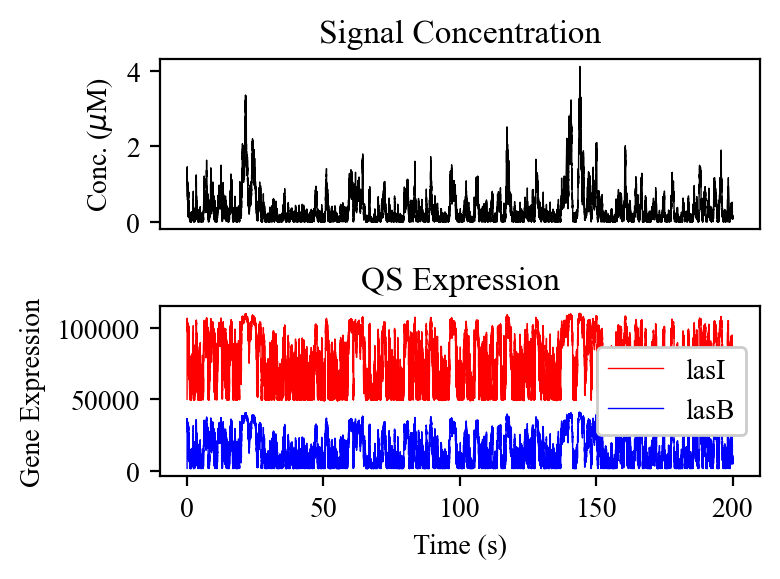

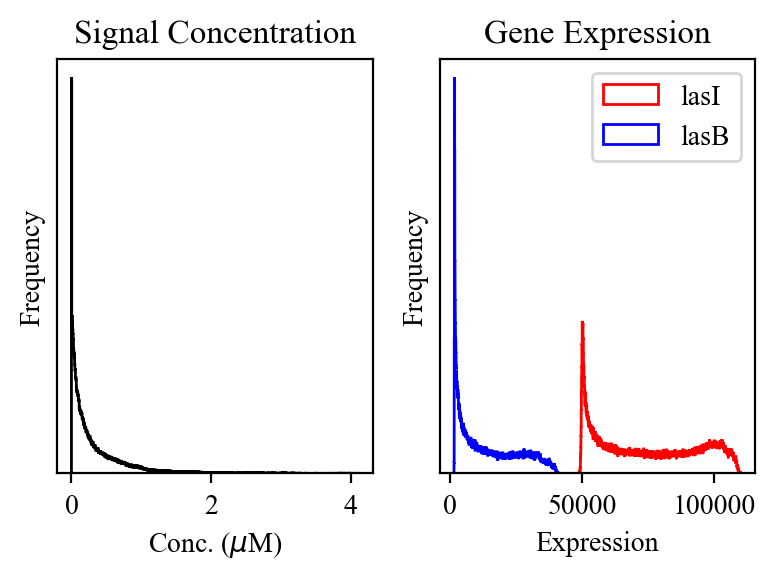

In [232]:
# Parameters
rho_I = 50000 # in [100, 2,000]
alpha_I = 60000 # in [10,000, 100,000]
K_I = 0.25 # in [0,1]
delta = 1 # in [0,2]
N = 0.1 # in [0,2]
c = 1.5e-5 # in [1e-6, 1e-4]
T_I = 1e-3 # Not sure of the parameter range

rho_B = 1588
alpha_B = 40000
K_B = 0.4
T_B = 1e-3

mm_pow = 1.5

def expression_lasI(S):
    return rho_I + (alpha_I*np.pow(S,mm_pow)) / (np.pow(K_I,mm_pow) + np.pow(S,mm_pow))

def expression_lasB(S):
    return rho_B + (alpha_B*np.pow(S,mm_pow)) / (np.pow(K_B,mm_pow) + np.pow(S,mm_pow))

def mu_S(S):
    return c*expression_lasI(S)*N - delta*S

def sigma_S(S):
    return np.sqrt(c*expression_lasI(S)*N + delta*S)

def mu_I(S,E):
    return expression_lasI(S) - E

def sigma_I(S,E):
    return np.sqrt(expression_lasI(S) + E)

def mu_B(S,E):
    return expression_lasB(S) - E

def sigma_B(S,E):
    return np.sqrt(expression_lasB(S) + E)

def Euler_step(X, dt):
    S, E_I, E_B = X
    S_new = S + mu_S(S)*dt + sigma_S(S)*np.sqrt(dt)*np.random.normal()
    E_I_new = E_I + mu_I(S,E_I)*dt/T_I + sigma_I(S,E_I)*np.sqrt(dt/T_I)*np.random.normal()
    E_B_new = E_B + mu_B(S,E_B)*dt/T_B + sigma_B(S,E_B)*np.sqrt(dt/T_B)*np.random.normal()
    return np.array([S_new, E_I_new, E_B_new])

dt = 0.001
tmax = 200
S0 = 1
E_I0 = rho_I
E_B0 = rho_B

num_time_steps = int(tmax / dt)
t_array = np.arange(0, tmax, dt)
sol_array = np.zeros((3, num_time_steps))
sol_array[:,0] = np.array([S0, E_I0, E_B0])

for i in range(1, num_time_steps):
    sol_array[:,i] = Euler_step(sol_array[:,i-1], dt)
    sol_array[np.argwhere(sol_array[:,i] < 0),i] = 0

S_time_series = sol_array[0]
expr_I_time_series = sol_array[1]
expr_B_time_series = sol_array[2]

fig, axes = plt.subplots(2, 1, figsize=(4,3), dpi=200)

ax1, ax2 = axes
ax1.plot(t_array, S_time_series, label=r'$S(t)$', color='k', linewidth=0.5)
ax2.plot(t_array, expr_I_time_series, label='lasI', color='r', linewidth=0.5)
ax2.plot(t_array, expr_B_time_series, label='lasB', color='b', linewidth=0.5)

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

ax1.set_ylabel('Conc. ($\\mu$M)')
ax2.set_ylabel('Gene Expression')

ax1.set_xticks([])
ax2.set_xlabel('Time (s)')

ax2.legend(framealpha=1)

plt.tight_layout()
plt.savefig('Figures/population-signal-lasI-lasB-SDE-time-series.png', bbox_inches='tight')

fig, axes = plt.subplots(1, 2, figsize=(4,3), dpi=200)

ax1, ax2 = axes

num_hist_bins = 1000
ax1.hist(S_time_series, bins=num_hist_bins, histtype='step', color='k')
ax2.hist(expr_I_time_series, bins=num_hist_bins, histtype='step', color='r', label='lasI')
ax2.hist(expr_B_time_series, bins=num_hist_bins, histtype='step', color='b', label='lasB')

ax1.set_title('Signal Concentration')
ax2.set_title('Gene Expression')

ax1.set_xlabel('Conc. ($\\mu$M)')
ax2.set_xlabel('Expression')

[ax.set_ylabel('Frequency') for ax in axes]
[ax.set_yticks([]) for ax in axes]

ax2.legend()

fig.tight_layout()

plt.savefig('Figures/population-signal-lasI-lasB-SDE-time-series-distributions.png', bbox_inches='tight')

### But that's way too much noise if the number of signal molecules is of order $10^{17}$ per mole...

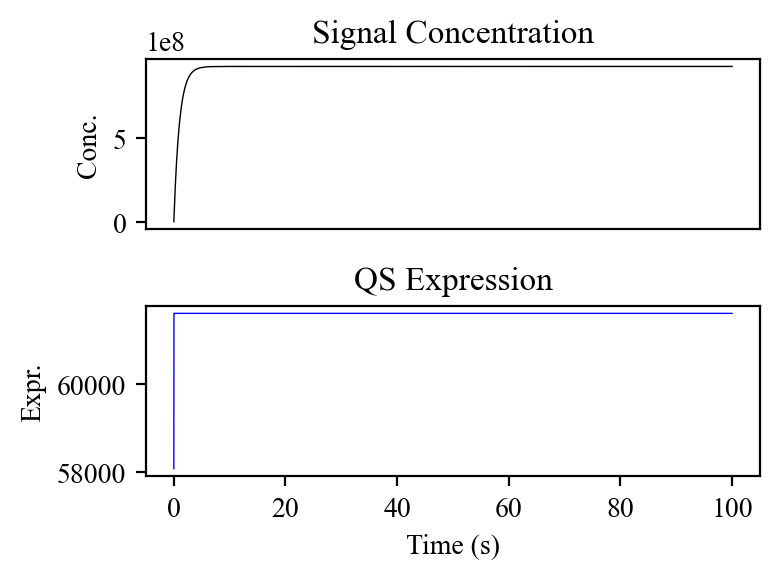

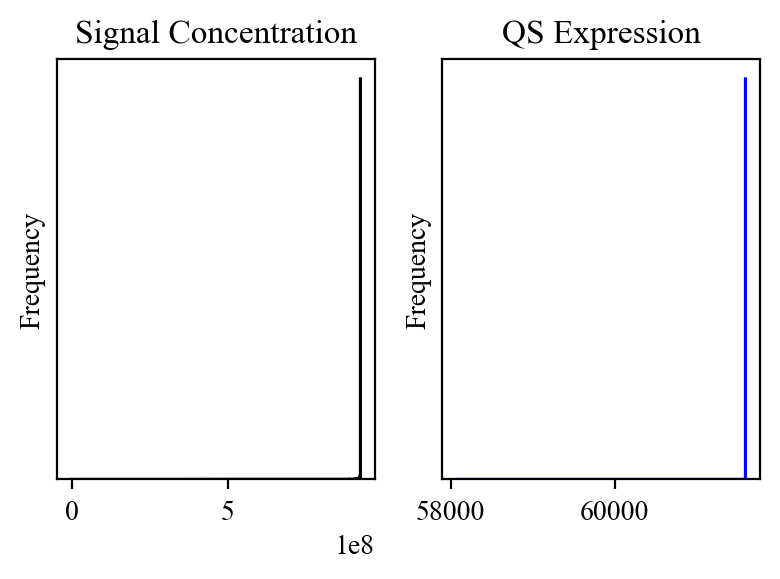

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 10

S0 = 1
dt = 0.001
tmax = 100

# Parameters
rho = 1600 # in [100, 2,000]
alpha = 60000 # in [10,000, 100,000]
K = 0.25 # in [0,1]
delta = 1 # in [0,2]
N = 1 # in [0,2]
c = 1.5e4 # in [1e-6, 1e-4]

def QS_expression(S):
    return rho + (alpha*np.pow(S,2)) / (np.pow(K,2) + np.pow(S,2))

def mu(S):
    return c*QS_expression(S)*N - delta*S

def sigma(S):
    return np.sqrt(c*QS_expression(S)*N)

def Euler_step(S, dt):
    return S + mu(S)*dt + sigma(S)*np.sqrt(dt)*np.random.normal()

num_time_steps = int(tmax / dt)
t_array = np.arange(0, tmax, dt)
S_time_series = np.zeros(num_time_steps)
S_time_series[0] = S0

for i in range(1, num_time_steps):
    S_time_series[i] = Euler_step(S_time_series[i-1], dt)
    if S_time_series[i] < 0: S_time_series[i] = 0 # boundary condition

QS_expression_time_series = QS_expression(S_time_series)
fig, axes = plt.subplots(2, 1, figsize=(4,3), dpi=200)

ax1, ax2 = axes
ax1.plot(t_array, S_time_series, label=r'$S(t)$', color='k', linewidth=0.5)
ax2.plot(t_array, QS_expression_time_series, label=r'$E(t)$', color='b', linewidth=0.5)

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

ax1.set_ylabel('Conc.')
ax2.set_ylabel('Expr.')

ax1.set_xticks([])
ax2.set_xlabel('Time (s)')

plt.tight_layout()
plt.savefig('Figures/single-signal-SDE-time-series-no-decay-noise.png', bbox_inches='tight')

fig, axes = plt.subplots(1, 2, figsize=(4,3), dpi=200)

ax1, ax2 = axes

num_hist_bins = 1000
ax1.hist(S_time_series, bins=num_hist_bins, histtype='step', color='k')
ax2.hist(QS_expression_time_series, bins=num_hist_bins, histtype='step', color='b')

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

[ax.set_ylabel('Frequency') for ax in axes]
[ax.set_yticks([]) for ax in axes]

fig.tight_layout()

plt.savefig('Figures/single-signal-SDE-time-series-distributions-no-decay-noise.png', bbox_inches='tight')

### So when we account for the fact that the number of particles is large, the noise goes away. What about if we include the SDE for expression?

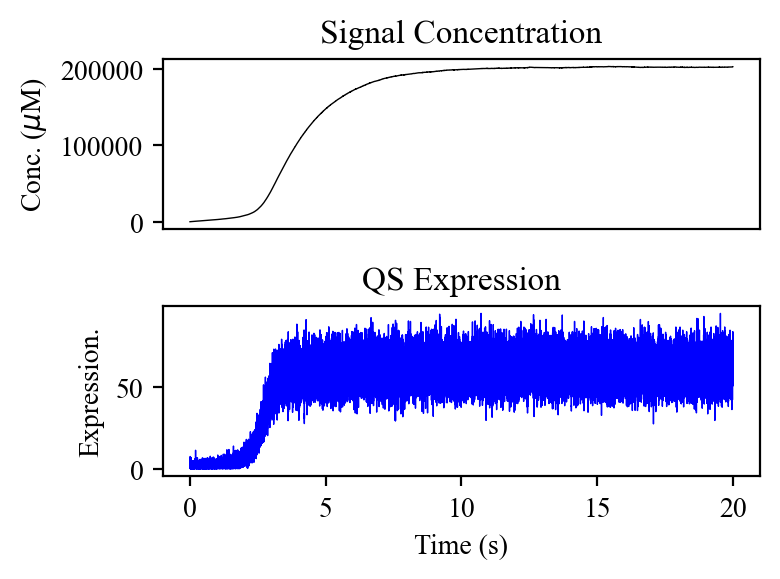

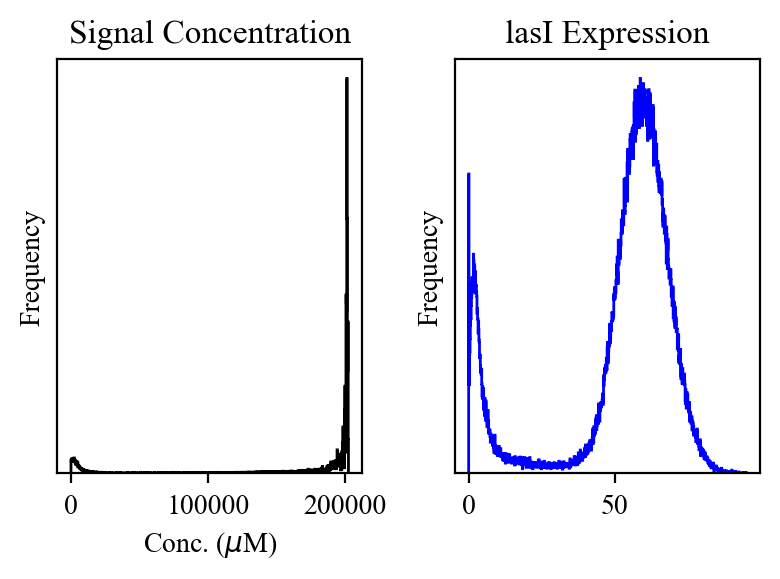

In [29]:
small_number_RNA_correction = 1e-3

S0 = 1
E0 = 1600*small_number_RNA_correction
dt = 0.0001
tmax = 20

# Parameters
rho = 1600 # in [100, 2,000]
alpha = 60000 # in [10,000, 100,000]
K = 0.25 # in [0,1]
delta = 0.6 # in [0,2]
N = 2 # in [0,2]
T = 1e-3 # Not sure of the parameter range

concentration_correction_factor = 1e5
c = 1e-5*concentration_correction_factor # in [1e-6, 1e-4]

def QS_expression(S):
    S = S / concentration_correction_factor
    return rho + (alpha*np.pow(S,2)) / (np.pow(K,2) + np.pow(S,2))

def mu_S(S):
    return c*QS_expression(S)*N - delta*S

def sigma_S(S):
    return np.sqrt(c*QS_expression(S)*N + delta*S)

def mu_E(S,E):
    return small_number_RNA_correction*(QS_expression(S)) - E

def sigma_E(S,E):
    return np.sqrt(small_number_RNA_correction*(QS_expression(S)) + E)

additional_expression_noise = lambda E: np.sqrt(E)

def Euler_step(X, dt):
    S, E = X
    S = S + mu_S(S)*dt + sigma_S(S)*np.sqrt(dt)*np.random.normal()
    E = E + mu_E(S,E)*dt/T + sigma_E(S,E)*np.sqrt(dt/T)*np.random.normal()
    return np.array([S, E])

num_time_steps = int(tmax / dt)
t_array = np.linspace(0, tmax, num_time_steps, endpoint=True)
sol_array = np.zeros((2, num_time_steps))
sol_array[:,0] = np.array([S0, E0])

for i in range(1, num_time_steps):
    sol_array[:,i] = Euler_step(sol_array[:,i-1], dt)
    if sol_array[0,i] < 0: sol_array[0,i] = 0 # boundary condition
    if sol_array[1,i] < 0: sol_array[1,i] = 0 # boundary condition

S_time_series = sol_array[0]
E_time_series = sol_array[1]

fig, axes = plt.subplots(2, 1, figsize=(4,3), dpi=200)

ax1, ax2 = axes
ax1.plot(t_array, S_time_series, label=r'$S(t)$', color='k', linewidth=0.5)
ax2.plot(t_array, E_time_series, label=r'$E(t)$', color='b', linewidth=0.5)

ax1.set_title('Signal Concentration')
ax2.set_title('QS Expression')

ax1.set_ylabel('Conc. ($\\mu$M)')
ax2.set_ylabel('Expression.')

ax1.set_xticks([])
ax2.set_xlabel('Time (s)')

plt.tight_layout()
plt.savefig('Figures/population-signal-and-expression-SDE-time-series.png', bbox_inches='tight')

fig, axes = plt.subplots(1, 2, figsize=(4,3), dpi=200)

ax1, ax2 = axes

num_hist_bins = 1000
ax1.hist(S_time_series, bins=num_hist_bins, histtype='step', color='k')
ax2.hist(E_time_series, bins=num_hist_bins, histtype='step', color='b')

ax1.set_title('Signal Concentration')
ax2.set_title('lasI Expression')

ax1.set_xlabel('Conc. ($\\mu$M)')
ax2.set_ylabel('Expression')

[ax.set_ylabel('Frequency') for ax in axes]
[ax.set_yticks([]) for ax in axes]

fig.tight_layout()

plt.savefig('Figures/population-signal-and-expression-SDE-time-series-distributions.png', bbox_inches='tight')